In [ ]:
# Empirical analysis: OECD PISA 2018

In [1]:
import pandas as pd
import statsmodels.stats.api as stats
import statsmodels.formula.api as smf
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

In [2]:
# Importing dataset into dataframe
df_learn = pd.read_csv('PISA-2018-GBR.csv')
df_learn

,math_score,read_score,scie_score,gender,immig,homelang,desk,room,quietplace,homecomputer,...,wealth,ictres,schlregion,schllocation,schltype,stratio,schsize,clsize,schid,stuid
0,408.95099,385.14871,426.54361,Female,Second-Generation,Other language,Yes,No,No,No,...,-1.2991,-1.2471,Great Britain: England,A large city (with over 1 000 000 people),Public,15.8053,893,21-25 students,82600001,82603288
1,467.38870,541.75861,488.95981,Female,Second-Generation,Language of the test,Yes,Yes,Yes,Yes,...,-1.4297,-0.3419,Great Britain: England,A large city (with over 1 000 000 people),Public,15.8053,893,21-25 students,82600001,82604013
2,392.49649,300.32700,323.72211,Female,Second-Generation,Other language,Yes,Yes,Yes,Yes,...,-0.7750,-1.2014,Great Britain: England,A large city (with over 1 000 000 people),Public,15.8053,893,21-25 students,82600001,82604218
3,574.38092,584.90240,529.17432,Female,Native,Language of the test,Yes,Yes,Yes,Yes,...,1.4432,1.2943,Great Britain: England,A large city (with over 1 000 000 people),Public,15.8053,893,21-25 students,82600001,82608603
4,494.03201,573.52588,491.84161,Female,Second-Generation,Language of the test,Yes,No,Yes,Yes,...,-0.8366,0.2272,Great Britain: England,A large city (with over 1 000 000 people),Public,15.8053,893,21-25 students,82600001,82610123
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5999,408.89560,474.86411,474.02670,Female,First-Generation,Language of the test,Yes,Yes,Yes,Yes,...,0.7437,1.2943,Great Britain: Scotland,A small town (3 000 to about 15 000 people),Public,13.7479,818,26-30 students,82650117,82652486
6000,375.97501,424.91730,413.76730,Female,Native,Language of the test,No,Yes,Yes,Yes,...,0.6913,0.7693,Great Britain: Scotland,A small town (3 000 to about 15 000 people),Public,13.7479,818,26-30 students,82650117,82652708
6001,417.80231,452.36230,419.73901,Male,Native,Language of the test,Yes,Yes,Yes,Yes,...,0.7788,0.6901,Great Britain: Scotland,A small town (3 000 to about 15 000 people),Public,13.7479,818,26-30 students,82650117,82653350
6002,396.27051,340.53760,361.05740,Male,Native,Language of the test,Yes,Yes,Yes,Yes,...,0.0622,0.5236,Great Britain: Scotland,A small town (3 000 to about 15 000 people),Public,13.7479,818,26-30 students,82650117,82654133


In [3]:
# Establishing dataframe with dependent, independent and control variables 
df_use = df_learn[['math_score', 'read_score', 'scie_score','desk', 'room', 'quietplace', 'homecomputer', 'homeinternet', 'books', 'booksqty','gender', 'wealth', 'hisced']].copy()
df_use.dtypes

math_score      float64
read_score      float64
scie_score      float64
desk             object
room             object
quietplace       object
homecomputer     object
homeinternet     object
books            object
booksqty         object
gender           object
wealth          float64
hisced           object
dtype: object

In [4]:
# Data profiling 
value_counts = []
for col in df_use.select_dtypes(include =['object','category']).columns:
    counts = df_use[col].value_counts(dropna= False)
    for val, count in counts.items():
        value_counts.append({'Variable':col, 'Category': val,'Count':count})
pd.DataFrame(value_counts)

,Variable,Category,Count
0,desk,Yes,5382
1,desk,No,622
2,room,Yes,5461
3,room,No,543
4,quietplace,Yes,5446
5,quietplace,No,558
6,homecomputer,Yes,5550
7,homecomputer,No,454
8,homeinternet,Yes,5958
9,homeinternet,No,46


In [5]:
# Cleaning data
df_use = df_use.dropna()

In [6]:
binary_vars = ['desk','room','quietplace','homecomputer','homeinternet','books']
for col in binary_vars:
    df_use[col] = df_use[col].map({'Yes': 1, 'No': 0})

df_use['gender'] = df_use['gender'].map({'Female': 1, "Male": 0})

df_use

,math_score,read_score,scie_score,desk,room,quietplace,homecomputer,homeinternet,books,booksqty,gender,wealth,hisced
0,408.95099,385.14871,426.54361,1,0,0,0,1,1,26-100 books,1,-1.2991,"ISCED 3A, ISCED 4"
1,467.38870,541.75861,488.95981,1,1,1,1,1,1,11-25 books,1,-1.4297,"ISCED 5A, 6"
2,392.49649,300.32700,323.72211,1,1,1,1,1,1,11-25 books,1,-0.7750,ISCED 5B
3,574.38092,584.90240,529.17432,1,1,1,1,1,1,More than 500 books,1,1.4432,"ISCED 5A, 6"
4,494.03201,573.52588,491.84161,1,0,1,1,1,1,11-25 books,1,-0.8366,ISCED 5B
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5999,408.89560,474.86411,474.02670,1,1,1,1,1,1,0-10 books,1,0.7437,"ISCED 3B, C"
6000,375.97501,424.91730,413.76730,0,1,1,1,1,1,0-10 books,1,0.6913,"ISCED 3B, C"
6001,417.80231,452.36230,419.73901,1,1,1,1,1,1,0-10 books,0,0.7788,"ISCED 3B, C"
6002,396.27051,340.53760,361.05740,1,1,1,1,1,0,0-10 books,0,0.0622,"ISCED 5A, 6"


In [7]:
bookqty_dummies = pd.get_dummies(
    df_use['booksqty'],
    prefix = 'booksqty',
    drop_first = True
)
df_use = pd.concat([df_use, bookqty_dummies], axis = 1)

In [8]:
hisced_dummies = pd.get_dummies(
    df_use['hisced'],
    prefix = 'hisced'
)
hisced_dummies = hisced_dummies.drop(columns = 'hisced_ISCED 5A, 6')
df_use = pd.concat([df_use, hisced_dummies], axis = 1)
df_use = df_use.drop(columns=['hisced']).copy()

In [9]:
df_use

,math_score,read_score,scie_score,desk,room,quietplace,homecomputer,homeinternet,books,booksqty,...,booksqty_101-200 books,booksqty_11-25 books,booksqty_201-500 books,booksqty_26-100 books,booksqty_More than 500 books,hisced_ISCED 1,hisced_ISCED 2,"hisced_ISCED 3A, ISCED 4","hisced_ISCED 3B, C",hisced_ISCED 5B
0,408.95099,385.14871,426.54361,1,0,0,0,1,1,26-100 books,...,False,False,False,True,False,False,False,True,False,False
1,467.38870,541.75861,488.95981,1,1,1,1,1,1,11-25 books,...,False,True,False,False,False,False,False,False,False,False
2,392.49649,300.32700,323.72211,1,1,1,1,1,1,11-25 books,...,False,True,False,False,False,False,False,False,False,True
3,574.38092,584.90240,529.17432,1,1,1,1,1,1,More than 500 books,...,False,False,False,False,True,False,False,False,False,False
4,494.03201,573.52588,491.84161,1,0,1,1,1,1,11-25 books,...,False,True,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5999,408.89560,474.86411,474.02670,1,1,1,1,1,1,0-10 books,...,False,False,False,False,False,False,False,False,True,False
6000,375.97501,424.91730,413.76730,0,1,1,1,1,1,0-10 books,...,False,False,False,False,False,False,False,False,True,False
6001,417.80231,452.36230,419.73901,1,1,1,1,1,1,0-10 books,...,False,False,False,False,False,False,False,False,True,False
6002,396.27051,340.53760,361.05740,1,1,1,1,1,0,0-10 books,...,False,False,False,False,False,False,False,False,False,False


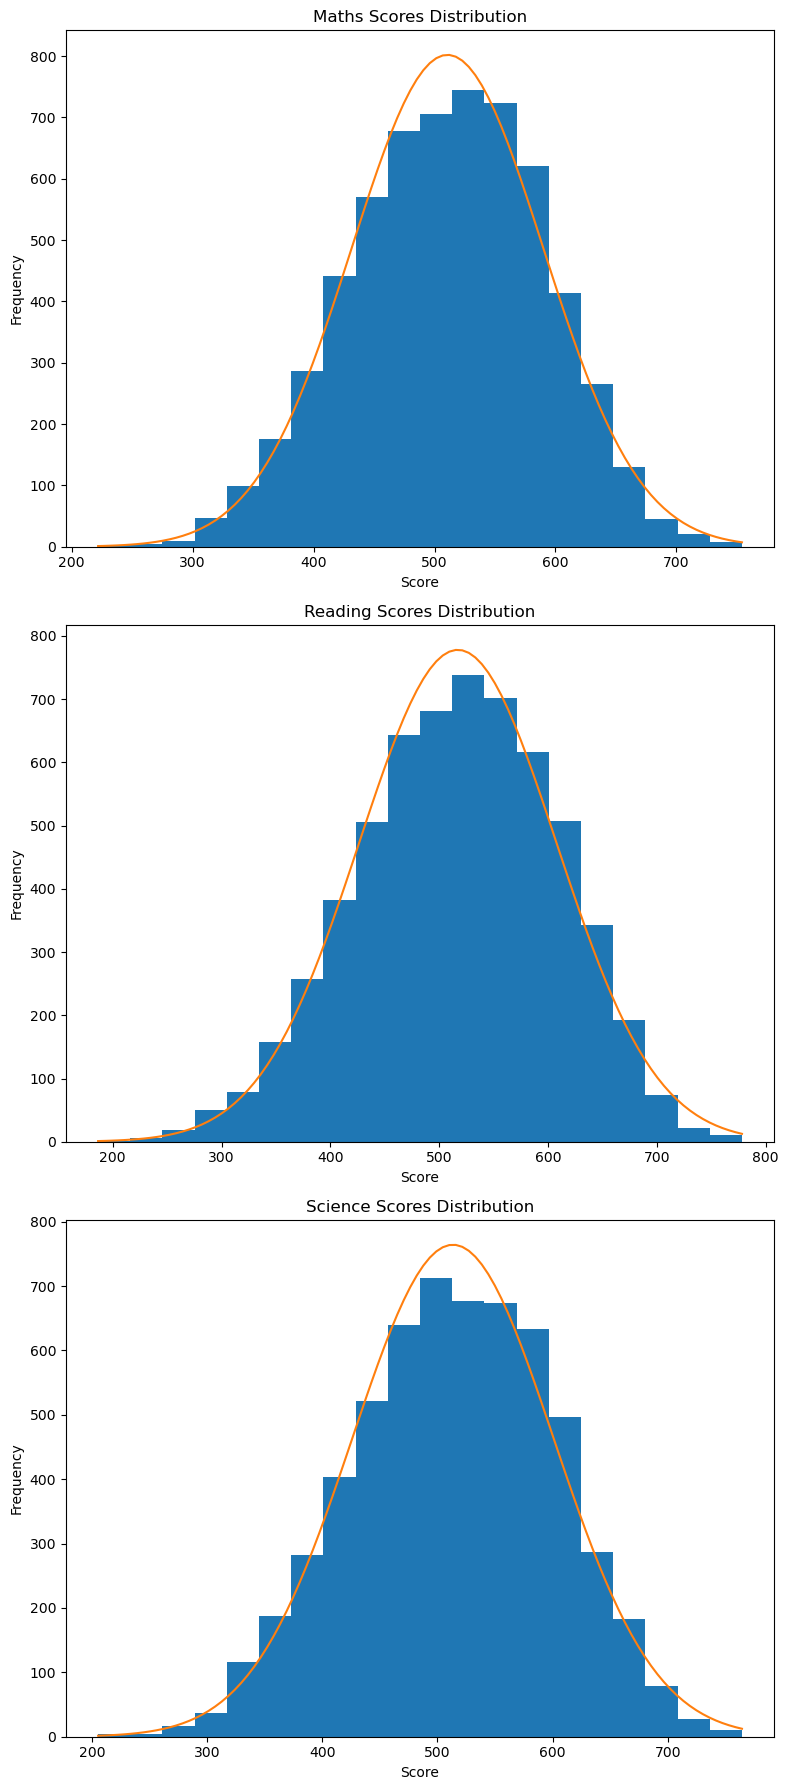

In [11]:
# Creating data visualisations 
scores = ['math_score', 'read_score', 'scie_score']
titles = ['Maths', 'Reading', 'Science']

fig, axs = plt.subplots(3, 1, figsize=(8, 18))

for i, score in enumerate(scores):
    data = df_use[score]
    
    counts, bins, _ = axs[i].hist(data, bins=20)
    
    mu, std = norm.fit(data)
    
    x = np.linspace(bins[0], bins[-1], 100)
    
    bin_width = bins[1] - bins[0]
    scaled_pdf = norm.pdf(x, mu, std) * len(data) * bin_width
    
    axs[i].plot(x, scaled_pdf)
    
    axs[i].set_title(f'{titles[i]} Scores Distribution')
    axs[i].set_xlabel('Score')
    axs[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

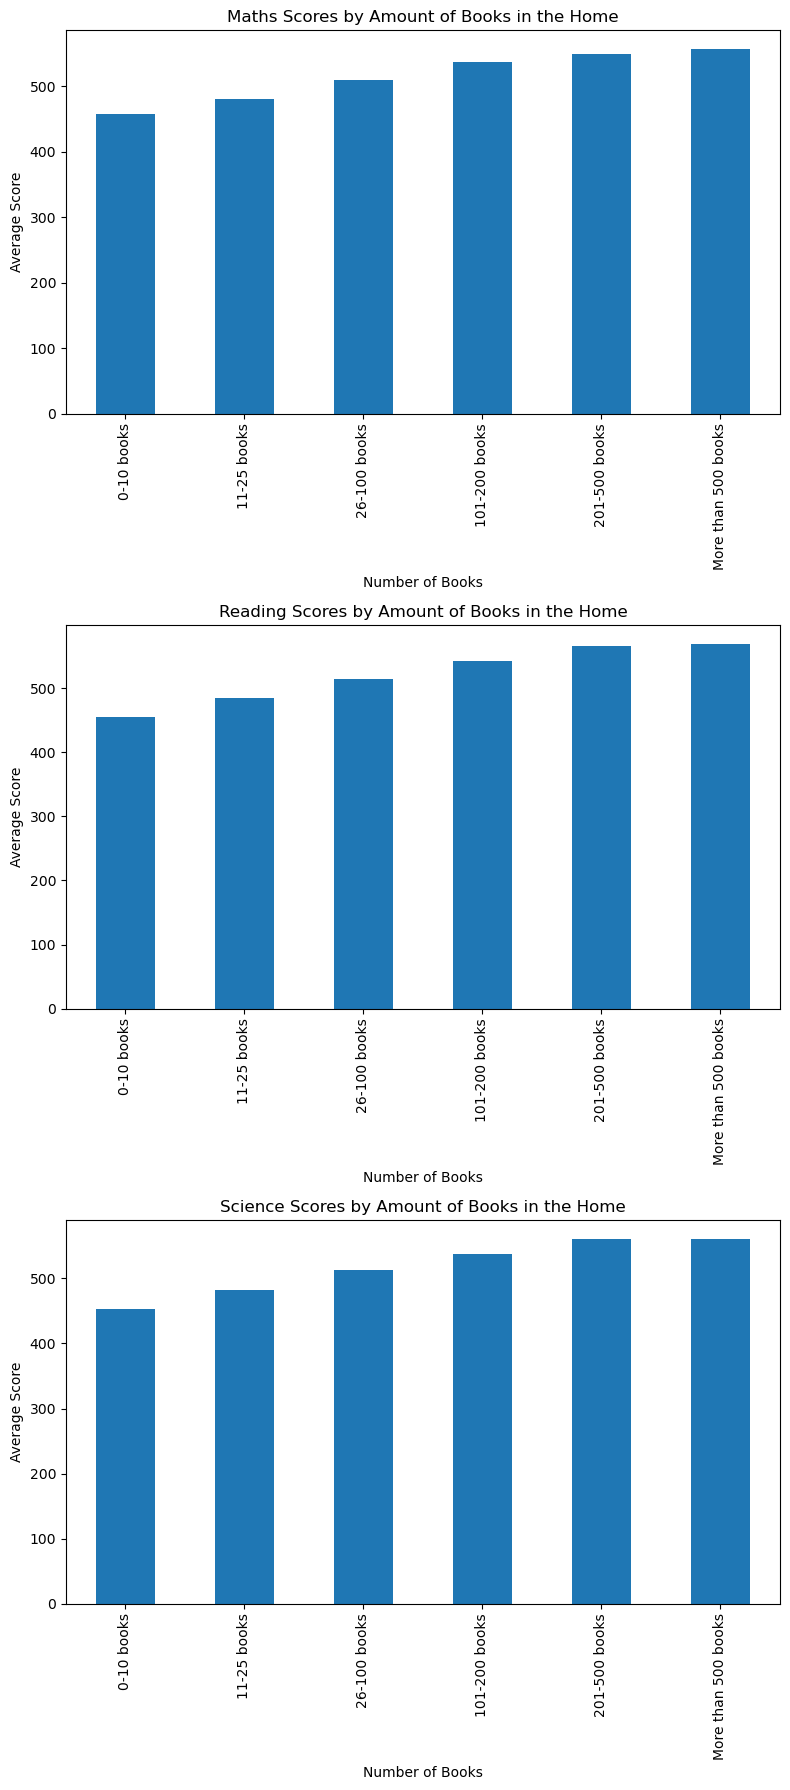

In [12]:
fig, axs = plt.subplots(3, 1, figsize=(8, 18))

correct_order = ['0-10 books', '11-25 books', '26-100 books', '101-200 books', '201-500 books', 'More than 500 books']

for i, score in enumerate(scores):
    df_use.groupby('booksqty')[score].mean().reindex(correct_order).plot(kind='bar', ax=axs[i])
    axs[i].set_title(f"{titles[i]} Scores by Amount of Books in the Home")
    axs[i].set_xlabel('Number of Books')
    axs[i].set_ylabel('Average Score')

plt.tight_layout()
plt.show()

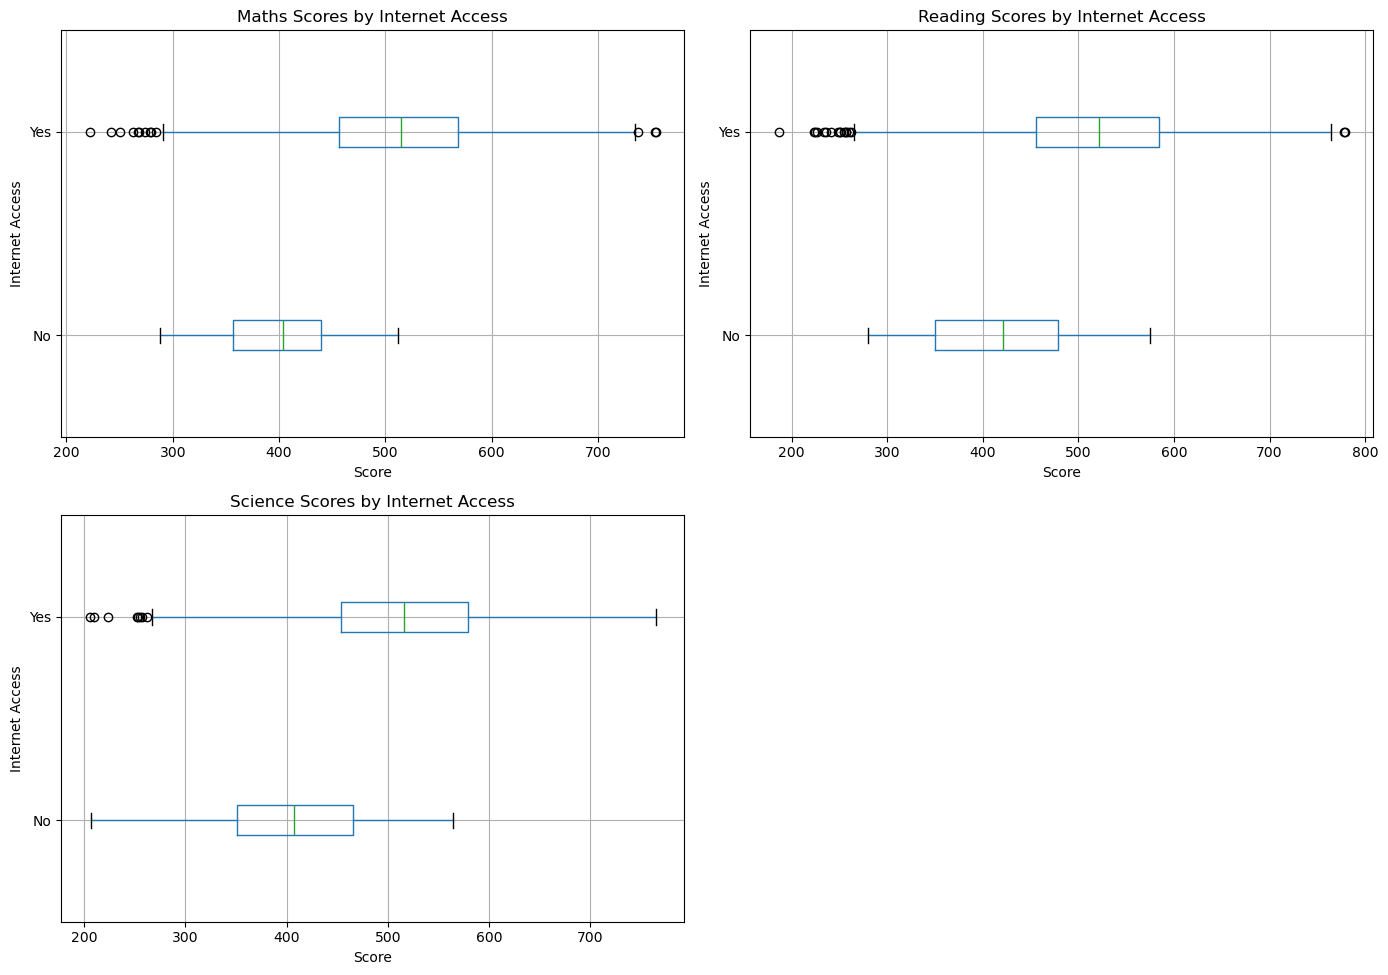

In [13]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

axs = axs.flatten()

for i, score in enumerate(scores):
    df_use.boxplot(column=score, by='homeinternet', ax=axs[i], vert = False)
    
    axs[i].set_title(f'{titles[i]} Scores by Internet Access')
    axs[i].set_xlabel('Score')
    axs[i].set_ylabel('Internet Access')

    axs[i].set_yticklabels(['No','Yes'])

fig.delaxes(axs[3])

plt.suptitle('')
plt.tight_layout()
plt.show()

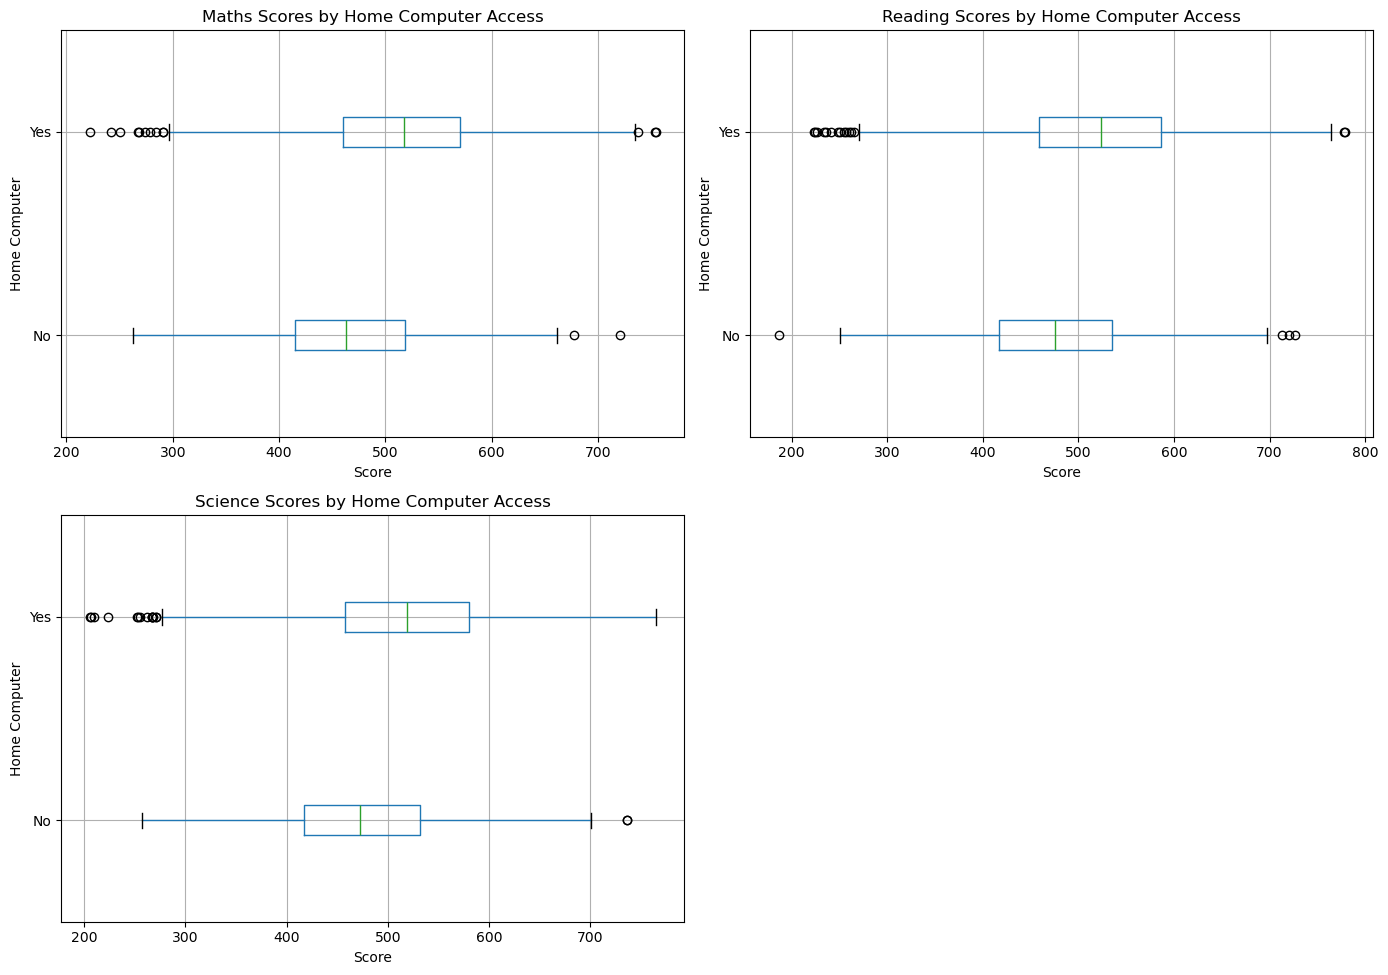

In [14]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

axs = axs.flatten()

for i, score in enumerate(scores):
    df_use.boxplot(column=score, by='homecomputer', ax=axs[i], vert = False)
    
    axs[i].set_title(f'{titles[i]} Scores by Home Computer Access')
    axs[i].set_xlabel('Score')
    axs[i].set_ylabel('Home Computer')
    axs[i].set_yticklabels(['No','Yes'])

fig.delaxes(axs[3])

plt.suptitle('')
plt.tight_layout()
plt.show()

In [15]:
# Running OLS regressions for each subject 
variables = 'desk + room + quietplace + homecomputer + homeinternet + books + Q("booksqty_11-25 books") + Q("booksqty_26-100 books") + Q("booksqty_101-200 books") + Q("booksqty_201-500 books") + Q("booksqty_More than 500 books") + gender + wealth + Q("hisced_ISCED 1") + Q("hisced_ISCED 2") + Q("hisced_ISCED 3A, ISCED 4") + Q("hisced_ISCED 3B, C") + Q("hisced_ISCED 5B")'

for score in scores:
    formula = f'{score} ~ {variables}'
    model = smf.ols(formula = formula, data = df_use).fit()
    print(f'REGRESSION FOR {score}')
    print(model.summary())
    print('\n'*8)
    

REGRESSION FOR math_score
                            OLS Regression Results                            
Dep. Variable:             math_score   R-squared:                       0.214
Model:                            OLS   Adj. R-squared:                  0.212
Method:                 Least Squares   F-statistic:                     90.40
Date:                Mon, 12 Oct 2026   Prob (F-statistic):          2.47e-295
Time:                        23:04:19   Log-Likelihood:                -33968.
No. Observations:                5989   AIC:                         6.797e+04
Df Residuals:                    5970   BIC:                         6.810e+04
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                                                coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------